# Prop-Firm Analysis 

One consistent pipeline built around various strategies. Set the knobs in Cell 2, then
**Run All**. Every cell uses the same `bars`, `E`, `g`, and `strat`.


In [8]:
pip install plotly

Note: you may need to restart the kernel to use updated packages.


## Firm rules ($50K)


In [6]:
for k, f in FIRMS.items():
    print(f"{k:17s} {f.name:26s} dd={f.dd_type.value:14s} lock={str(f.trail_lock):7s} "
          f"DLL={str(f.daily_loss_limit):5s}({f.dll_behavior.value:4s}) "
          f"cons={str(f.consistency_pct):4s} min_days={f.min_days}")

apex_eod          Apex (EOD Trailing)        dd=eod_trail      lock=50000   DLL=1000 (hard) cons=None min_days=1
apex_intraday     Apex (Intraday Trailing)   dd=intraday_trail lock=50000   DLL=None (none) cons=None min_days=1
lucid             Lucid (LucidPro)           dd=eod_trail      lock=50000   DLL=1200 (hard) cons=None min_days=1
tradeify_select   Tradeify (Select)          dd=eod_trail      lock=50000   DLL=None (none) cons=0.4  min_days=3
tradeify_growth   Tradeify (Growth)          dd=eod_trail      lock=50000   DLL=1250 (soft) cons=None min_days=1
mffu_rapid        MyFundedFutures (Rapid)    dd=intraday_trail lock=None    DLL=None (none) cons=0.5  min_days=2
topstep           Topstep (Combine)          dd=eod_trail      lock=50000   DLL=None (none) cons=0.5  min_days=2


## Verify Project Directory and Testing KNOBS Setups

In [1]:
import os, sys
SEARCH_ROOT = r"C:\\Users\\2115h\\Desktop\\Trading"
PROJECT_DIR = next((r for r, d, f in os.walk(SEARCH_ROOT)
                    if "Firms.py" in f and "__pycache__" not in r), os.getcwd())
os.chdir(PROJECT_DIR); sys.path.insert(0, PROJECT_DIR)
print("Project dir:", PROJECT_DIR)

Project dir: C:\\Users\\2115h\\Desktop\\Trading\Propfirm Convex Analysis\Rules


In [ ]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt
from Firms import FIRMS, get_firm
from Strategy import EmpiricalStrategy
from Strategy import Timewindow
from Backtest import load_ohlc, backtest_entries, ledger_for_rr, measured_winrate
from Analysis import (risk_geometry_3d, oos_check,
                      plot_risk_geometry_3d, plot_top_cells, summary_table_3d)
from Surface3d import surface_by_stop, scatter_4d, write_html
from Engine import simulate

# Each strategy owns how to build it, its data prep, and its exit defaults.
# NOTE: no more k_stop_atr — the stop is a SWEEP AXIS now (STOP_GRID in cell 6).
STRATEGIES = {
    "new_jj_5min": dict(
        build   = lambda p: __import__("strategies.new_jj_5min", fromlist=["NewJJ"]).NewJJ(
                      bos_tf="5min", swing_k=p.get("swing_k", 2)),
        rth_only=True, timeframe=None, max_hold=60,
        params  = dict(swing_k=2),
    ),
    "new_jj_3min": dict(
        build   = lambda p: __import__("strategies.new_jj_5min", fromlist=["NewJJ"]).NewJJ(
                      bos_tf="3min", swing_k=p.get("swing_k", 2)),
        rth_only=True, timeframe=None, max_hold=60,
        params  = dict(swing_k=2),
    ),
    "kernel_pullback": dict(
        build   = lambda p: __import__("strategies.kernel_pullback", fromlist=["get_strategy"]).get_strategy(**p),
        rth_only=True, timeframe="3min", max_hold=40,
        params  = dict(h=8.0, r=8.0, x_0=5,
                       wait_bars=5, slope_len=1, slope_min=0.2,
                       allow_long=True, allow_short=True),
    ),
    "kernel_pullback_1": dict(
        build   = lambda p: __import__("strategies.kernel_pullback_1", fromlist=["get_strategy"]).get_strategy(**p),
        rth_only=True, timeframe="3min", max_hold=40,
        params  = dict(h=8.0, r=8.0, x_0=5,
                       pullback_bars=10, slope_len=1, slope_min=0.02,
                       allow_long=True, allow_short=True),
    ),
    "kernel_fvg": dict(
        build   = lambda p: __import__("strategies.kernel_fvg", fromlist=["get_strategy"]).get_strategy(**p),
        rth_only=True, timeframe="3min", max_hold=100,
        params  = dict(h=8.0, r=8.0, x_0=10, er_len=15, er_min=0.2,
                       fvg_tfs=(2, 3, 4, 5), min_tf_agree=0, fvg_lookback=15, agree=3,
                       allow_long=True, allow_short=True),
    ),
    "kernel": dict(
        build   = lambda p: __import__("strategies.kernel", fromlist=["get_strategy"]).get_strategy(**p),
        rth_only=True, timeframe=None, max_hold=120,
        params  = dict(h=7.0, r=8.0, x_0=5, er_len=15, er_min=0.2, agree=3,
                       allow_long=True, allow_short=True),
    ),
    "kernel_bos": dict(
        build   = lambda p: Timewindow (__import__("strategies.kernel_bos", fromlist=["get_strategy"]).get_strategy(**p), start="09:30", end="11:00"),
        rth_only=True, timeframe="1min", max_hold=120,

        params  = dict(h=8.0, r=8.0, x_0=5, bos_lookback=5, require_flip=False, slope_len=1,
                       slope_min=0.3, er_min=0.0, allow_long=True, allow_short=True),
    ),
}


In [9]:
# ===================== THE ONLY CHOICES =====================
STRATEGY   = "kernel_bos"          # <-- switch strategy here, one line
FIRM       = get_firm("topstep")
DATA_PATH  = "data/NQ.ohlcv-1m.parquet"
STOP_GRID  = [25, 30, 35, 40, 45, 50]                       # POINTS — the swept stop axis
RR_GRID    = [0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 2.75, 3.0]
RISK_PCTS  = np.round(np.arange(0.25, 3.51, 0.25), 2)
MAX_HOLD   = 100
MAX_DAYS_TO_PASS = 10
N_PATHS    = 2000
ALL_FIRMS  = ["apex_eod","apex_intraday","lucid","tradeify_select",
              "tradeify_growth","mffu_rapid","topstep"]

OVERRIDES  = {}     # e.g. {"slope_min": 0.4} to override a registry param
# ============================================================
print("Active strategy:", STRATEGY)

Active strategy: kernel_bos


## Verify Parquest Data Loaded Correctly (Skip after first time)

In [22]:
PERIOD_START = "2025-01-01"
PERIOD_END = "2025-01-31"

bars_p = load_ohlc(DATA_PATH, rth_only=False, timeframe=None, tz="America/New_York")
bars_p = bars_p.loc[PERIOD_START:PERIOD_END]
print ("columns:", list(bars_p.columns), "| index tz:", bars_p.index.tz)

week = bars_p.loc["2025-01-06":"2025-01-10"]
print(f"\n{len(week)} bars in week {week.index.min().date()} -> {week.index.max().date()}")
print(week.iloc[::60].to_string())
print("\nprice sanity:", week["close"].min(), "-", week["close"].max())

columns: ['open', 'high', 'low', 'close'] | index tz: America/New_York

6090 bars in week 2025-01-06 -> 2025-01-10
                               open      high       low     close
datetime                                                         
2025-01-06 00:00:00-05:00  21523.25  21525.75  21520.50  21524.75
2025-01-06 01:00:00-05:00  21539.50  21544.50  21538.00  21539.75
2025-01-06 02:00:00-05:00  21549.00  21552.75  21546.00  21551.75
2025-01-06 03:00:00-05:00  21565.25  21569.50  21564.75  21565.25
2025-01-06 04:00:00-05:00  21617.75  21626.25  21616.50  21626.25
2025-01-06 05:00:00-05:00  21669.00  21672.50  21665.25  21667.50
2025-01-06 06:00:00-05:00  21670.25  21672.00  21665.50  21667.00
2025-01-06 07:00:00-05:00  21730.25  21736.50  21725.50  21735.00
2025-01-06 08:00:00-05:00  21735.00  21740.25  21731.00  21734.75
2025-01-06 09:00:00-05:00  21749.50  21752.50  21745.25  21749.25
2025-01-06 10:00:00-05:00  21818.25  21830.50  21814.00  21815.00
2025-01-06 11:00:00-05:00  

## 1) Sample test build entries + measured win rate by R:R


In [10]:
from edge_diagnostic import bracket_edge_grid

strat = STRATEGIES[STRATEGY]["build"]({**STRATEGIES[STRATEGY]["params"], **OVERRIDES})
bars  = load_ohlc(DATA_PATH, rth_only=STRATEGIES[STRATEGY]["rth_only"],
                  timeframe=STRATEGIES[STRATEGY]["timeframe"], tz="America/New_York")

print(f"edge bracket across STOP_GRID (rr=1.5):")
res = bracket_edge_grid(strat, bars, STOP_GRID, rr=1.5, max_hold=MAX_HOLD)
if not any(r["verdict"].startswith("EDGE") for r in res):
    print("\n>>> No stop beats random — stop here, the sweep has nothing to find.")

edge bracket across STOP_GRID (rr=1.5):
  stop=  25pt  edge=+0.042  WR=40.7%  n=2986  CI=[-0.000,+0.091]  cheat=+0.650 rand=-0.003  -> NOT distinguishable from zero
  stop=  30pt  edge=+0.037  WR=39.8%  n=2746  CI=[-0.012,+0.082]  cheat=+0.657 rand=+0.010  -> NOT distinguishable from zero
  stop=  35pt  edge=+0.047  WR=38.9%  n=2547  CI=[+0.005,+0.098]  cheat=+0.612 rand=+0.005  -> EDGE vs random (CI excludes 0)
  stop=  40pt  edge=+0.059  WR=38.0%  n=2378  CI=[+0.014,+0.104]  cheat=+0.610 rand=+0.030  -> EDGE vs random (CI excludes 0)
  stop=  45pt  edge=+0.044  WR=35.5%  n=2275  CI=[-0.003,+0.092]  cheat=+0.588 rand=-0.015  -> NOT distinguishable from zero
  stop=  50pt  edge=+0.028  WR=33.0%  n=2164  CI=[-0.016,+0.082]  cheat=+0.561 rand=+0.038  -> NOT distinguishable from zero


## 2) In-Sample and Out-Of-Sample (OOS) Walk-Forward Test

In [ ]:
from Walkforward import walk_forward
from Surface3d import surface_by_stop, scatter_4d, write_html

# strategy_factory(**swept) -> ready-to-backtest strategy.
# FIXED = params held constant; the grid below is what gets searched per fold.
_cfg = STRATEGIES[STRATEGY]
FIXED = dict(h=8.0, r=8.0, bos_lookback=5, require_flip=False, er_min=0.0,
             allow_long=True, allow_short=True)   # match your kernel_bos.py

def strategy_factory(**swept):
    inner = _cfg["build"]({**FIXED, **swept})       # build wraps in TimeWindow already
    return inner

# the SEARCH SPACE — swept inside every fold, never on the full sample
PARAM_GRID = {
    "x_0":       [3, 5, 8, 10],
    "slope_len": [1, 2, 3],
    "slope_min": [0.2, 0.3, 0.4],
}
# STOP_GRID, RR_GRID, RISK_PCTS, MAX_HOLD, MAX_DAYS_TO_PASS come from your KNOBS cell

In [6]:
bars = load_ohlc(DATA_PATH, rth_only=_cfg["rth_only"],
                 timeframe=_cfg["timeframe"], tz="America/New_York")

wf = walk_forward(
    FIRM, bars, strategy_factory, PARAM_GRID,
    stop_grid=STOP_GRID, risk_pcts=RISK_PCTS, rr_grid=RR_GRID,
    train_months=6, test_months=3, step_months=3, embargo_days=1,   # ~quarterly folds, ~40 min
    max_hold=MAX_HOLD, n_paths=1000, max_trades=300,
    min_trades=120, min_trades_per_day=1, max_days_to_pass=MAX_DAYS_TO_PASS,
    stage_a_top_n=5, selection="floor",
    multi_n_accounts=5, multi_max_days=25, seed=0)

print(f"\nPooled OOS single-account: {wf.pooled_test_pass_pct:.1f}%")
print(f"Pooled OOS 5-slot rotation: {wf.pooled_multi_pass_rate:.1f}%")
print(f"Walk-forward PBO: {wf.pbo:.2f}   (~0 good, ~0.5 = search is noise)")
wf.table()

[fold 0] 2021-12-01..2022-03-01  params={'x_0': 3, 'slope_len': 3, 'slope_min': 0.1}  50pt/2.5R@1.25%  train_floor=46 train_pass=69  -> TEST single=39% (n=150) multi=50% (5P/5B)
[fold 1] 2022-03-01..2022-06-01  params={'x_0': 3, 'slope_len': 3, 'slope_min': 0.1}  25pt/2R@0.75%  train_floor=45 train_pass=70  -> TEST single=47% (n=235) multi=40% (4P/6B)
[fold 2] 2022-06-01..2022-09-01  params={'x_0': 8, 'slope_len': 2, 'slope_min': 0.1}  40pt/0.5R@1.50%  train_floor=37 train_pass=55  -> TEST single=73% (n=136) multi=60% (3P/2B)
[fold 3] 2022-09-01..2022-12-01  params={'x_0': 10, 'slope_len': 1, 'slope_min': 0.2}  40pt/1R@1.25%  train_floor=37 train_pass=63  -> TEST single=56% (n=106) multi=67% (4P/2B)
[fold 4] 2022-12-01..2023-03-01  params={'x_0': 10, 'slope_len': 2, 'slope_min': 0.1}  25pt/0.75R@1.50%  train_floor=39 train_pass=58  -> TEST single=58% (n=150) multi=44% (4P/5B)
[fold 5] 2023-03-01..2023-06-01  params={'x_0': 10, 'slope_len': 1, 'slope_min': 0.1}  25pt/2.5R@0.75%  train_f

,fold,train,test,x_0,slope_len,slope_min,stop,rr,risk,train_pass,train_floor,test_pass,test_days,test_n,multi_pass,passed,blown,timeout,rank_pct,note
0,0,2021-06-01..2021-11-30,2021-12-01..2022-03-01,3,3,0.1,50.0,2.50,1.25,69.3,46.10,39.3,5.104326,150,50.000000,5,5,0,0.75,
1,1,2021-09-01..2022-02-28,2022-03-01..2022-06-01,3,3,0.1,25.0,2.00,0.75,69.9,45.05,46.8,9.711538,235,40.000000,4,6,0,0.25,
2,2,2021-12-01..2022-05-31,2022-06-01..2022-09-01,8,2,0.1,40.0,0.50,1.50,55.4,36.85,73.0,10.504110,136,60.000000,3,2,1,0.00,
3,3,2022-03-01..2022-08-31,2022-09-01..2022-12-01,10,1,0.2,40.0,1.00,1.25,63.2,37.30,56.0,10.825000,106,66.666667,4,2,1,0.25,
4,4,2022-06-01..2022-11-30,2022-12-01..2023-03-01,10,2,0.1,25.0,0.75,1.50,58.2,38.80,58.0,8.112069,150,44.444444,4,5,0,0.25,
5,5,2022-09-01..2023-02-28,2023-03-01..2023-06-01,10,1,0.1,25.0,2.50,0.75,57.0,39.40,26.9,10.784387,162,18.181818,2,9,0,0.50,
6,6,2022-12-01..2023-05-31,2023-06-01..2023-09-01,10,1,0.3,35.0,0.75,1.75,69.3,39.90,48.6,9.166667,79,28.571429,2,5,0,0.75,
7,7,2023-03-01..2023-08-31,2023-09-01..2023-12-01,8,1,0.3,50.0,0.50,2.50,61.7,39.70,43.8,9.500000,83,33.333333,3,6,0,0.00,
8,8,2023-06-01..2023-11-30,2023-12-01..2024-03-01,3,1,0.3,35.0,0.75,2.25,54.5,33.70,33.9,6.938053,108,35.714286,5,9,0,0.75,
9,9,2023-09-01..2024-02-29,2024-03-01..2024-06-01,10,2,0.3,50.0,0.50,3.50,51.4,29.70,27.7,7.101083,93,14.285714,2,12,0,1.00,


In [11]:
import numpy as np, plotly.graph_objects as go

F = [f for f in wf.folds if np.isfinite(f.test_pass_pct)]
x  = [f.stop_points for f in F]; y = [f.risk_pct for f in F]; z = [f.rr for f in F]
c  = [f.test_pass_pct for f in F]
cd = np.array([[f.fold.idx, f.multi_pass_rate, f.selected_params.get("x_0", np.nan),
                f.selected_params.get("slope_min", np.nan)] for f in F], float)

fig = go.Figure(go.Scatter3d(
    x=x, y=y, z=z, mode="markers",
    marker=dict(size=6, color=c, colorscale="RdYlGn", cmin=0, cmax=100,
                colorbar=dict(title="OOS pass %")),
    customdata=cd,
    hovertemplate=("fold %{customdata[0]:.0f}<br>stop %{x}pt  risk %{y}%  R:R %{z}<br>"
                   "OOS pass <b>%{marker.color:.0f}%</b><br>rotation %{customdata[1]:.0f}%<br>"
                   "x_0=%{customdata[2]:.0f}  slope_min=%{customdata[3]:.2f}<extra></extra>")))
fig.update_layout(scene=dict(xaxis_title="stop (pts)", yaxis_title="risk %", zaxis_title="R:R"),
                  title="Varied-param walk-forward: each fold's picked geometry vs OOS pass", height=640)
fig.show()

In [12]:
FIXED = dict(h=8.0, r=8.0, x_0=8, bos_lookback=8, slope_len=1, slope_min=0.1,
             require_flip=False, er_min=0.0, allow_long=True, allow_short=True)
def strategy_factory(**swept):
    return Timewindow(__import__("strategies.kernel_bos", fromlist=["get_strategy"])
                      .get_strategy(**{**FIXED, **swept}), start="09:30", end="11:00")

PARAM_GRID = {}                                  # no indicator sweep
STOP_GRID  = [35, 40, 45]                            # justified by your bracket (35–40 cleared random)
RISK_PCTS  = np.round(np.arange(0.5, 2.01, 0.25), 2)                            # single risk
RR_GRID    = [0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0]   # the swept axis

wf_rr = walk_forward(
    FIRM, bars, strategy_factory, PARAM_GRID,
    stop_grid=STOP_GRID, risk_pcts=RISK_PCTS, rr_grid=RR_GRID,
    train_months=6, test_months=3, step_months=3, embargo_days=1,
    max_hold=MAX_HOLD, n_paths=1000, max_trades=300,
    min_trades=120, min_trades_per_day=0.15, max_days_to_pass=MAX_DAYS_TO_PASS,
    stage_a_top_n=1, selection="floor", multi_n_accounts=5, multi_max_days=25, seed=0)

print(f"\nRR-only  | pooled OOS single: {wf_rr.pooled_test_pass_pct:.1f}%  "
      f"rotation: {wf_rr.pooled_multi_pass_rate:.1f}%")
print("selected R:R per fold:", [f.rr for f in wf_rr.folds if f.selected_params is not None or True])
wf_rr.table()

[fold 0] 2021-12-01..2022-03-01  params={}  35pt/2.5R@1.00%  train_floor=40 train_pass=51  -> TEST single=39% (n=183) multi=40% (4P/6B)
[fold 1] 2022-03-01..2022-06-01  params={}  45pt/2R@1.25%  train_floor=38 train_pass=54  -> TEST single=31% (n=153) multi=42% (5P/7B)
[fold 2] 2022-06-01..2022-09-01  params={}  35pt/0.5R@1.50%  train_floor=33 train_pass=55  -> TEST single=33% (n=159) multi=27% (3P/8B)
[fold 3] 2022-09-01..2022-12-01  params={}  35pt/1R@1.25%  train_floor=32 train_pass=59  -> TEST single=20% (n=142) multi=27% (3P/8B)
[fold 4] 2022-12-01..2023-03-01  params={}  40pt/1.75R@1.75%  train_floor=31 train_pass=42  -> TEST single=36% (n=130) multi=50% (5P/5B)
[fold 5] 2023-03-01..2023-06-01  params={}  45pt/1.75R@1.75%  train_floor=33 train_pass=44  -> TEST single=39% (n=104) multi=44% (4P/5B)
[fold 6] 2023-06-01..2023-09-01  params={}  40pt/2.5R@1.25%  train_floor=32 train_pass=39  -> TEST single=41% (n=114) multi=42% (5P/7B)
[fold 7] 2023-09-01..2023-12-01  params={}  40pt/0

,fold,train,test,stop,rr,risk,train_pass,train_floor,test_pass,test_days,test_n,multi_pass,passed,blown,timeout,rank_pct,note
0,0,2021-06-01..2021-11-30,2021-12-01..2022-03-01,35.0,2.50,1.00,51.3,39.750,39.4,6.829949,183,40.000000,4,6,0,NaN,
1,1,2021-09-01..2022-02-28,2022-03-01..2022-06-01,45.0,2.00,1.25,54.1,37.525,31.1,5.151125,153,41.666667,5,7,0,NaN,
2,2,2021-12-01..2022-05-31,2022-06-01..2022-09-01,35.0,0.50,1.50,55.3,32.800,33.0,12.515152,159,27.272727,3,8,0,NaN,
3,3,2022-03-01..2022-08-31,2022-09-01..2022-12-01,35.0,1.00,1.25,58.6,32.500,19.5,10.625641,142,27.272727,3,8,1,NaN,
4,4,2022-06-01..2022-11-30,2022-12-01..2023-03-01,40.0,1.75,1.75,42.2,30.700,35.5,4.219718,130,50.000000,5,5,0,NaN,
5,5,2022-09-01..2023-02-28,2023-03-01..2023-06-01,45.0,1.75,1.75,43.8,32.800,38.7,6.824289,104,44.444444,4,5,1,NaN,
6,6,2022-12-01..2023-05-31,2023-06-01..2023-09-01,40.0,2.50,1.25,39.3,31.700,40.7,7.083538,114,41.666667,5,7,0,NaN,
7,7,2023-03-01..2023-08-31,2023-09-01..2023-12-01,40.0,0.75,2.00,54.5,36.425,26.1,6.712644,128,15.789474,3,16,0,NaN,
8,8,2023-06-01..2023-11-30,2023-12-01..2024-03-01,45.0,0.75,2.00,46.7,27.275,33.0,8.112121,95,41.666667,5,7,0,NaN,
9,9,2023-09-01..2024-02-29,2024-03-01..2024-06-01,35.0,0.50,2.00,41.2,24.000,26.6,9.082707,125,18.750000,3,13,0,NaN,


## 3) Optimal risk geometry for the chosen firm

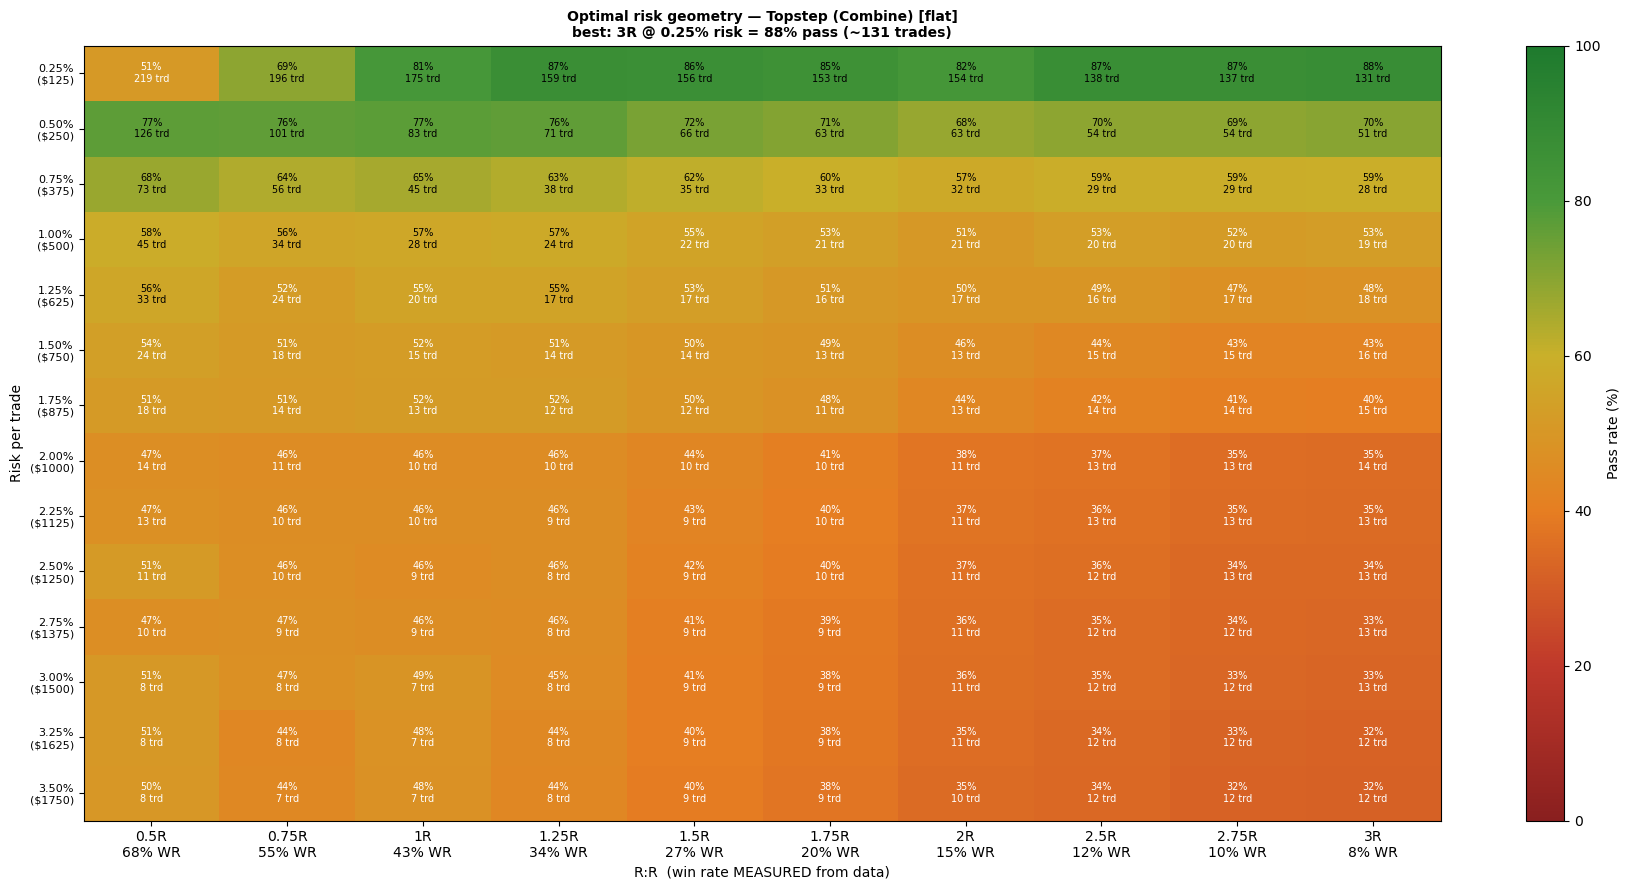

BEST for Topstep (Combine): 3R @ 0.25% risk -> 88% pass in ~131 trades (WR 8%)


In [35]:
fig, g = risk_rr_heatmap(FIRM, E, risk_pcts=RISK_PCTS, rr_grid=RR_GRID,
                         n_paths=2000, max_trades=300); plt.show()
print(f"BEST for {FIRM.name}: {g['opt_rr']:g}R @ {g['opt_risk_pct']:.2f}% risk "
      f"-> {g['opt_pass_pct']:.0f}% pass in ~{g['opt_speed']:.0f} trades (WR {g['opt_wr']:.0%})")

In [7]:
from Backtest import load_ohlc
bars = load_ohlc(DATA_PATH, rth_only=False, timeframe=None, tz="America/New_York")
print("rows:", len(bars))
print("range:", bars.index.min(), "->", bars.index.max())
print("has 2025:", (bars.index.year == 2025).any())
print("has 2026:", (bars.index.year == 2026).any())

rows: 1767373
range: 2021-06-27 20:00:00-04:00 -> 2026-06-26 16:59:00-04:00
has 2025: True
has 2026: True


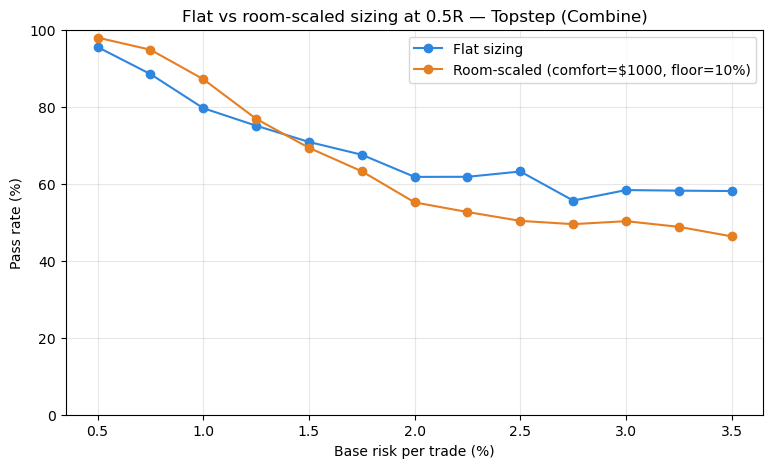

BEST room-scaled: 0.50% base risk -> 98% pass (flat at same risk: 96%)


In [8]:
# === ROOM-SCALED SIZING vs FLAT (size down in drawdown, steady when safe) ===
R_rs, days_rs = ledger_for_rr(E, g["opt_rr"])          # ledger at the heatmap's best R:R
strat_rs = EmpiricalStrategy(R_rs, name=f"new_jj {g['opt_rr']:g}R", day_ids=days_rs)

rp_axis = RISK_PCTS[RISK_PCTS >= 0.5]
flat_p, scaled_p = [], []
for rp in rp_axis:
    rd = FIRM.start_balance * rp / 100
    flat_p.append(simulate(strat_rs, FIRM, rd, n_paths=4000, max_trades=300,
                           sizing="flat").pass_rate * 100)
    scaled_p.append(simulate(strat_rs, FIRM, rd, n_paths=4000, max_trades=300,
                             sizing="room_scaled", comfort_room=COMFORT_ROOM,
                             min_risk_frac=MIN_RISK_FRAC).pass_rate * 100)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(rp_axis, flat_p,   "-o", color="#2e86de", label="Flat sizing")
ax.plot(rp_axis, scaled_p, "-o", color="#e67e22",
        label=f"Room-scaled (comfort=${COMFORT_ROOM}, floor={MIN_RISK_FRAC:.0%})")
ax.set_xlabel("Base risk per trade (%)"); ax.set_ylabel("Pass rate (%)"); ax.set_ylim(0, 100)
ax.set_title(f"Flat vs room-scaled sizing at {g['opt_rr']:g}R — {FIRM.name}")
ax.legend(); ax.grid(alpha=.3); plt.show()

bi = int(np.argmax(scaled_p))
print(f"BEST room-scaled: {rp_axis[bi]:.2f}% base risk -> {scaled_p[bi]:.0f}% pass "
      f"(flat at same risk: {flat_p[bi]:.0f}%)")

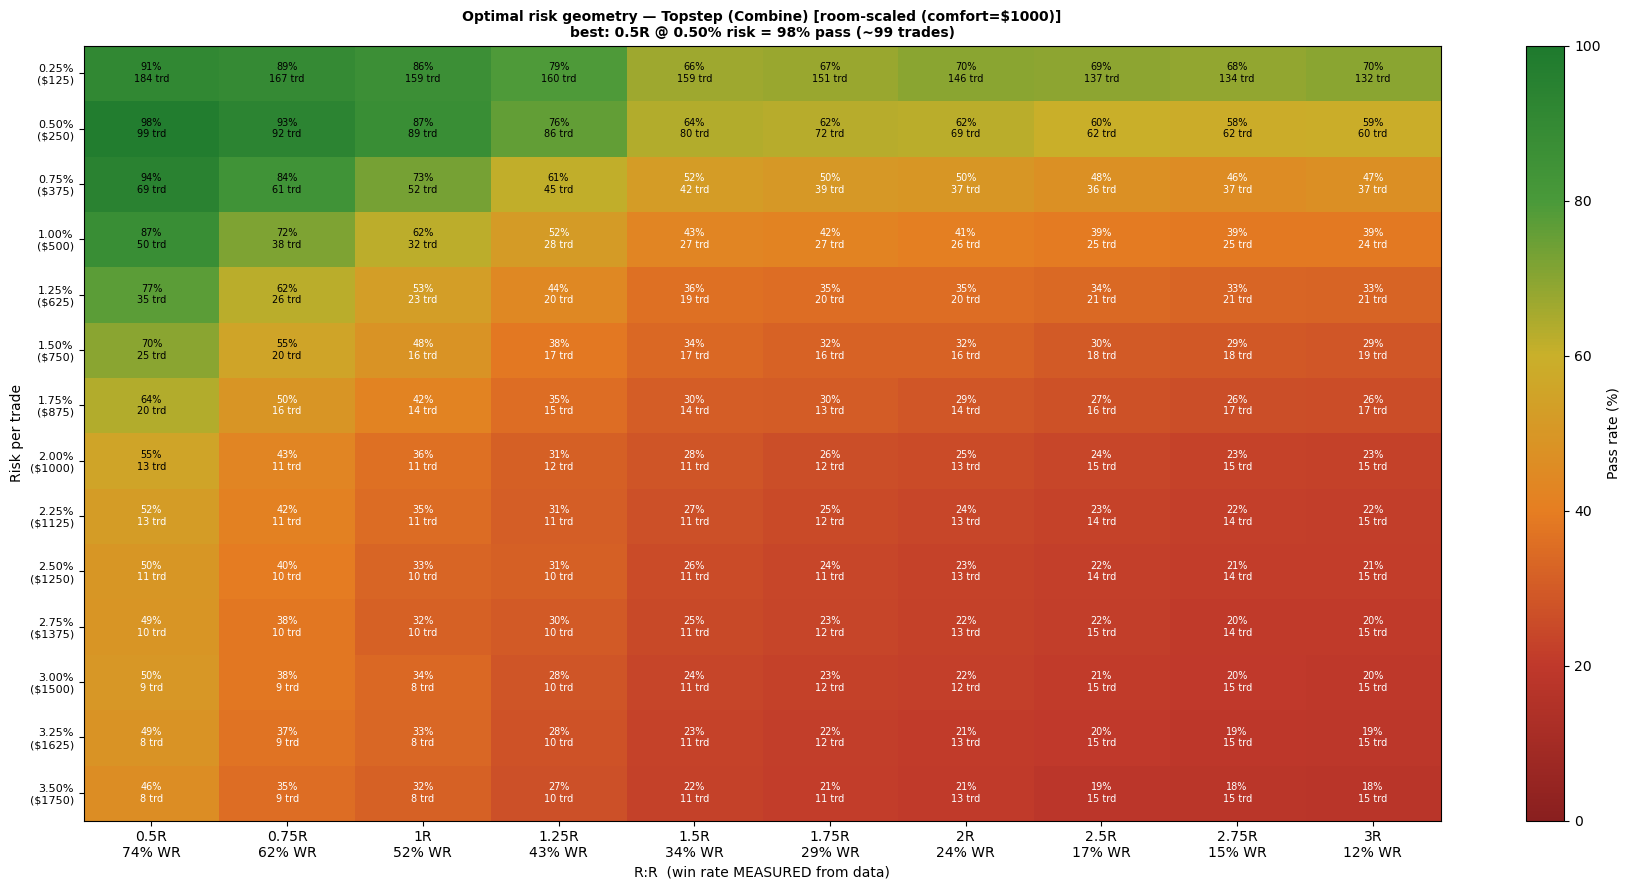

ROOM-SCALED best: 0.5R @ 0.50% risk -> 98% pass in ~99 trades


In [9]:
# === SAME HEATMAP, ROOM-SCALED SIZING ===
fig, g_rs = risk_rr_heatmap(FIRM, E, risk_pcts=RISK_PCTS, rr_grid=RR_GRID,
                            n_paths=2000, max_trades=300,
                            sizing="room_scaled",
                            comfort_room=COMFORT_ROOM, min_risk_frac=MIN_RISK_FRAC)
plt.show()
print(f"ROOM-SCALED best: {g_rs['opt_rr']:g}R @ {g_rs['opt_risk_pct']:.2f}% risk "
      f"-> {g_rs['opt_pass_pct']:.0f}% pass in ~{g_rs['opt_speed']:.0f} trades")

### 2) Optimal Risk Geometry for Designated Months (i.e 2025 June - November)

2026-01-01 to 2026-06-30: 47,938 bars, 125 days
211 entries over 124 days (~1.70 trades/day) | new_jj on ?


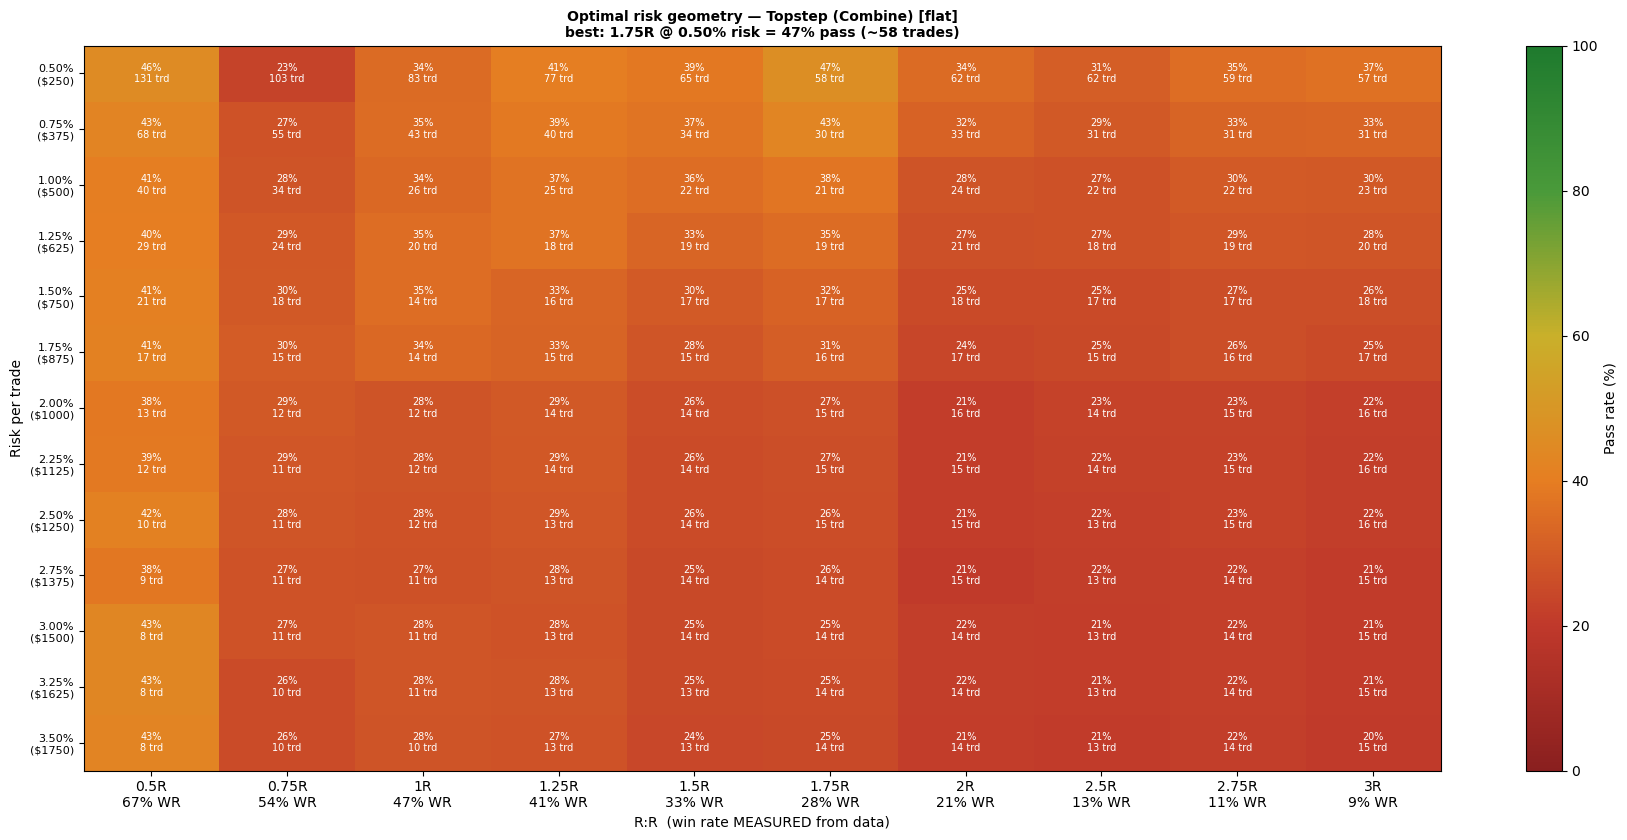

BEST (2026-01): 1.75R @ 0.50% -> 47% pass in ~58 trades (WR 28%)


In [10]:
PERIOD_START = "2026-01-01"
PERIOD_END = "2026-06-30"

bars_p = load_ohlc(DATA_PATH, rth_only=True, timeframe=None, tz="America/New_York")
bars_p = bars_p.loc[PERIOD_START:PERIOD_END]
print (f"{PERIOD_START} to {PERIOD_END}: {len(bars_p):,} bars, "
         f"{bars_p.index.normalize().nunique()} days")

E = backtest_entries(NewJJ(bos_tf=BOS_TF, swing_k=SWING_K), bars_p,
                     k_stop_atr=K_STOP_ATR, max_hold=MAX_HOLD)
print(E.summary())

RISK_PCTS_NO025 = RISK_PCTS[RISK_PCTS >= 0.5]   # ignore the 0.25% option

fig, g_p = risk_rr_heatmap(FIRM, E, risk_pcts=RISK_PCTS_NO025, rr_grid=RR_GRID,
                           n_paths=2000, max_trades=300); plt.show()
print(f"BEST ({PERIOD_START[:7]}): {g_p['opt_rr']:g}R @ {g_p['opt_risk_pct']:.2f}% "
      f"-> {g_p['opt_pass_pct']:.0f}% pass in ~{g_p['opt_speed']:.0f} trades "
      f"(WR {g_p['opt_wr']:.0%})")

### Risk Geometry Floor Optimization (!!!)
As shown above, different market periods produce different optimal risk-to-reward (R) settings because each month represents a distinct market regime. Averaging the results across all months provides a view of what worked on average, but this is of limited practical value. In live trading, we operate within a single market regime at a time—not the average of many.

To address this, the backtest is divided into an in-sample and an out-of-sample (OOS) period. Within the in-sample period, the data is further segmented into rolling two-month windows. A Risk × R parameter grid is evaluated on each window, and the resulting performance is assessed using robustness metrics, including the mean pass rate, minimum pass rate, and standard deviation.

The key idea behind this approach is to optimize for the **floor** rather than the **average**. For example, a parameter combination that achieves an average pass rate of 65% but falls to 20% during unfavorable months is less desirable than one that averages 58% but never drops below 45%. The latter is consistently tradable across different market regimes, whereas the former depends heavily on encountering favorable conditions. 

This concept on rboustness aims to identify paramter regions that remain **relatively** resilient acorss changing regimes, thereby reducing the likelihood of severe performance degradation in future. Ultimately, the simulator is not intended to have predictive value, its sole purpose is to identify risk geometery / configurations that have demonstrated the greatest stability across a range of historical conditions.

IS windows: 55 | OOS windows: 6


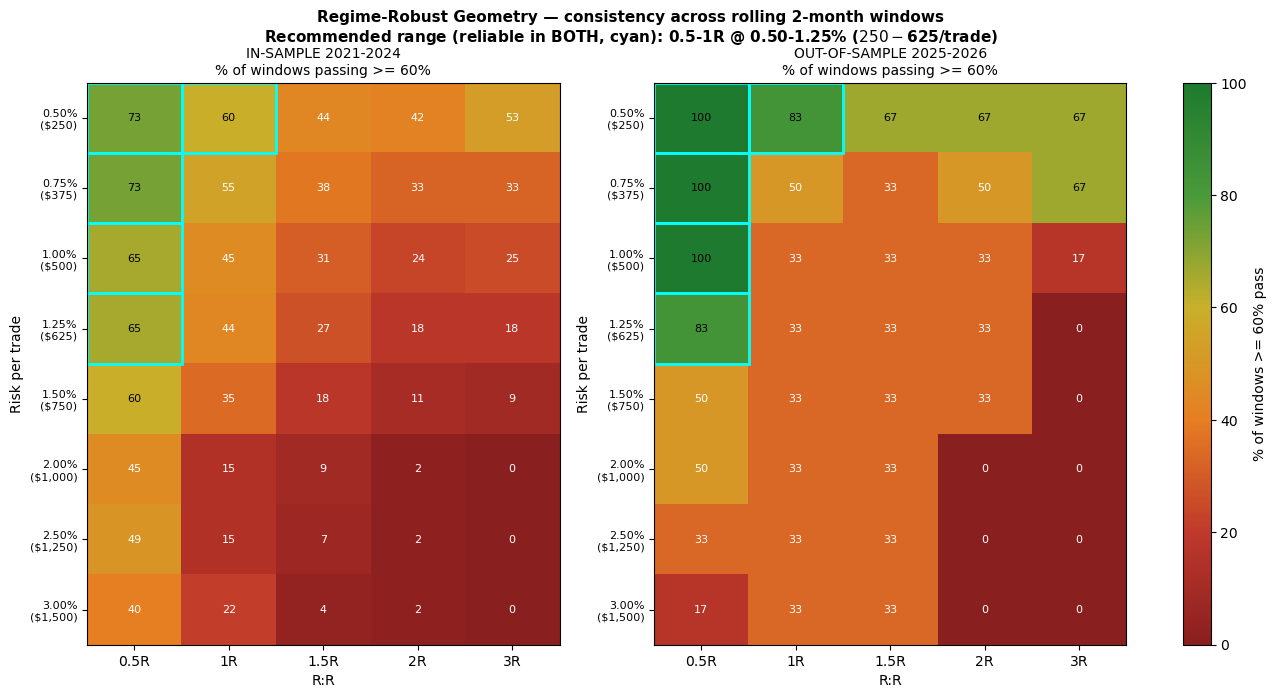


>>> RECOMMENDED RANGE: 0.5-1R @ 0.50-1.25% ($250-$625/trade), reliable in >=60% of windows in BOTH periods



,RR,risk_%,risk_$,IS_mean,IS_floor_p25,IS_worst,IS_%win>=60,OOS_mean,OOS_%win>=60,robust_score
0,0.50,0.50,$250,74,51,1,73,87,100,73
1,0.50,0.75,$375,72,54,3,73,80,100,73
2,0.50,1.25,$625,65,48,9,65,68,83,65
3,0.50,1.00,$500,67,51,7,65,72,100,65
4,1.00,0.50,$250,61,23,0,60,70,83,60
5,3.00,0.50,$250,50,16,0,53,68,67,53
6,1.00,0.75,$375,57,25,2,55,65,50,50
7,0.50,1.50,$750,63,46,11,60,65,50,50
8,0.50,2.00,"$1,000",55,42,11,45,59,50,45
9,1.50,0.50,$250,50,16,1,44,68,67,44


In [11]:
# === REGIME-ROBUST GEOMETRY: rolling 2-month windows, IS vs OOS ===
import numpy as np, pandas as pd
from Robustness import window_pass_grids, plot_summary, summary_table
from strategies.new_jj import NewJJ

bars_all = load_ohlc(DATA_PATH, rth_only=False, timeframe=None, tz="America/New_York")
IS  = bars_all.loc["2021-01-01":"2025-12-31"]     # in-sample
OOS = bars_all.loc["2026-01-01":"2026-12-31"]     # out-of-sample (never tuned on)

factory = lambda: NewJJ(bos_tf=BOS_TF, swing_k=SWING_K)
RISK_R  = np.array([0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 2.5, 3.0])
RR_R    = [0.5, 1.0, 1.5, 2.0, 3.0]
THRESH  = 60     # "a good window" = pass rate >= this

is_grids,  _, isc = window_pass_grids(factory, IS,  FIRM, RISK_R, RR_R, k_stop_atr=K_STOP_ATR,
                                      months=2, step_months=1, n_paths=700, min_trades=25)
oos_grids, _, oc  = window_pass_grids(factory, OOS, FIRM, RISK_R, RR_R, k_stop_atr=K_STOP_ATR,
                                      months=2, step_months=1, n_paths=700, min_trades=25)
print(f"IS windows: {len(is_grids)} | OOS windows: {len(oos_grids)}")

fig, rec = plot_summary(is_grids, oos_grids, RISK_R, RR_R,
                        start_balance=FIRM.start_balance, threshold=THRESH); plt.show()

print(f"\n>>> RECOMMENDED RANGE: {rec['rr_lo']:g}-{rec['rr_hi']:g}R @ "
      f"{rec['risk_lo']:.2f}-{rec['risk_hi']:.2f}% "
      f"(${rec['dollar_lo']:,.0f}-${rec['dollar_hi']:,.0f}/trade), "
      f"reliable in >={rec['bar']:.0f}% of windows in BOTH periods\n")

tbl = summary_table(is_grids, oos_grids, RISK_R, RR_R, start_balance=FIRM.start_balance, threshold=THRESH)
fmt = {"RR":"{:.2f}","risk_%":"{:.2f}","risk_$":"${:,.0f}","IS_mean":"{:.0f}","IS_floor_p25":"{:.0f}",
       "IS_worst":"{:.0f}",f"IS_%win>={THRESH}":"{:.0f}","OOS_mean":"{:.0f}",
       f"OOS_%win>={THRESH}":"{:.0f}","robust_score":"{:.0f}"}
display(tbl.head(10).style.format(fmt).set_caption("Most robust geometries (reliable in both periods)"))

## 3) Risk curve + equity paths at the optimal R:R

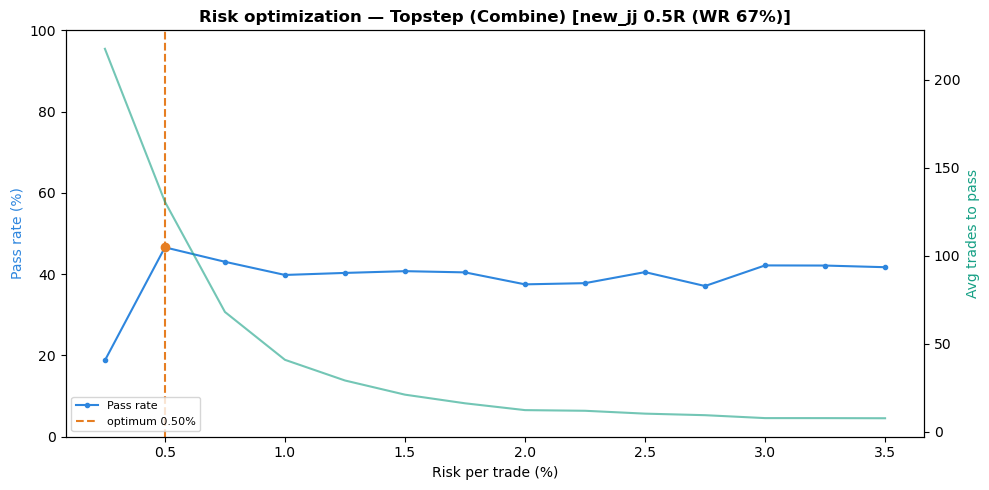

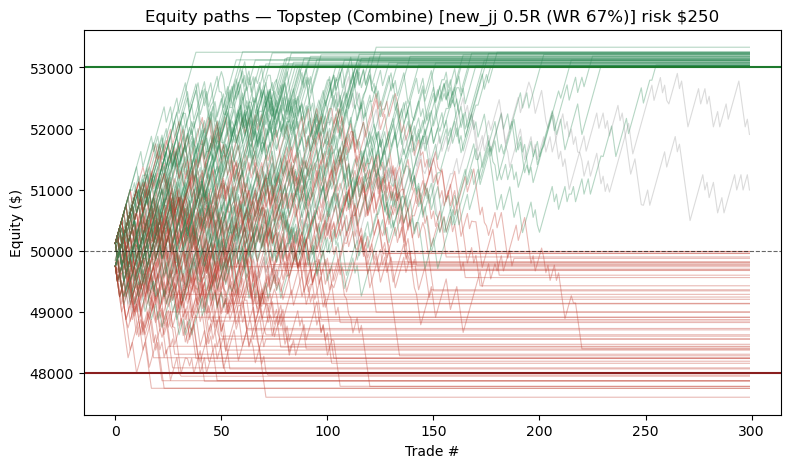

In [12]:
R, days = ledger_for_rr(E, g["opt_rr"])
strat = EmpiricalStrategy(R, name=f"new_jj {g['opt_rr']:g}R (WR {measured_winrate(E, g['opt_rr']):.0%})",
                          day_ids=days)
fig, r = plot_risk_curve(strat, FIRM, risk_pcts=RISK_PCTS, n_paths=3000, max_trades=300); plt.show()
fig = plot_equity_paths(FIRM, strat, risk_per_trade=r["opt_risk_dollars"],
                        n_show=120, max_trades=300); plt.show()

## 4) Cross-firm optimal risk

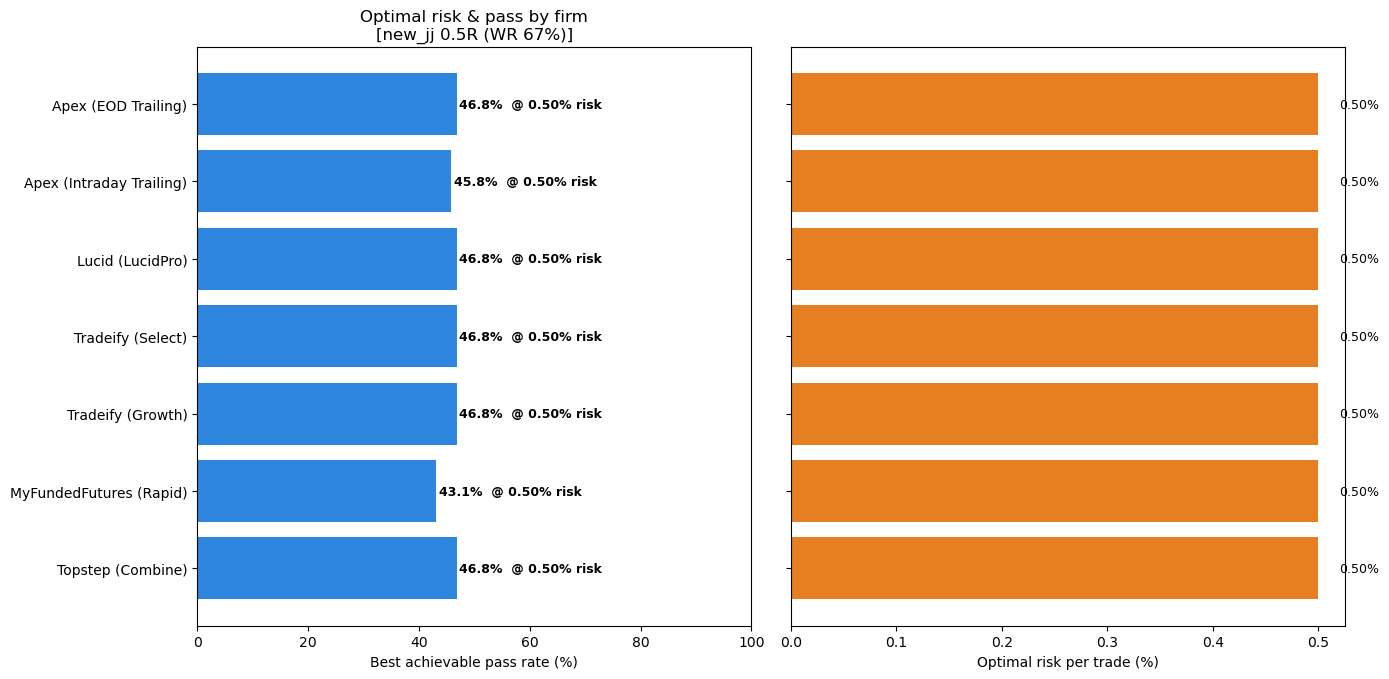

In [13]:
results, fig = optimal_risk_by_firm(strat, get_firm, ALL_FIRMS,
    risk_pcts=RISK_PCTS, n_paths=2500, max_trades=300); plt.show()

## 5) Time to pass by firm

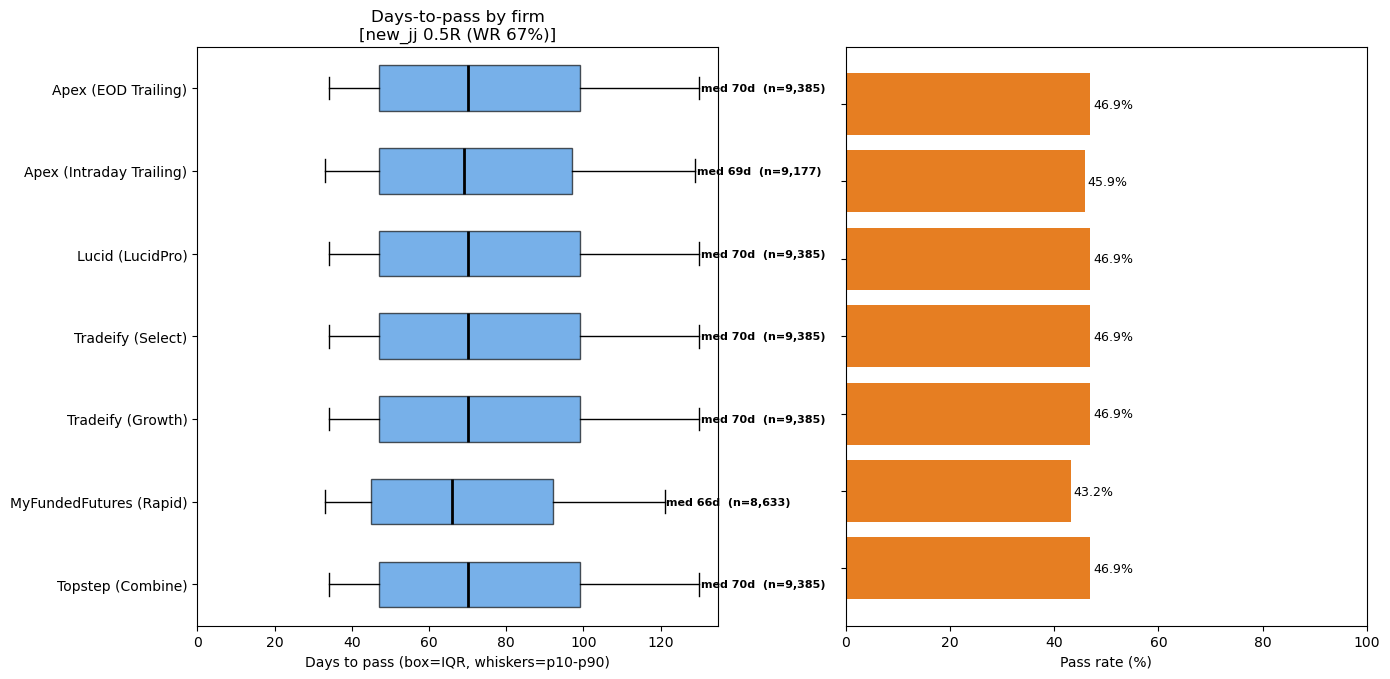

AttributeError: 'dict' object has no attribute 'to_string'

In [14]:
results, fig, summary = days_to_pass_by_firm(strat, get_firm, ALL_FIRMS,
    risk_pcts=RISK_PCTS, n_paths=2500, max_trades=300, dist_paths=20000); plt.show()
print(summary.to_string(index=False))

## Add-on — sweep stop width (K_STOP_ATR)
Independent of the cells above. Uses `K_STOP_ATR_GRID` from the KNOBS to find the
stop width with the best pass rate for this firm.

In [ ]:
rows = []
for kstop in K_STOP_ATR_GRID:
    Ek = backtest_entries(NewJJ(bos_tf=BOS_TF, swing_k=SWING_K), bars,
                          k_stop_atr=kstop, max_hold=MAX_HOLD)
    if len(Ek.day_ids) < 100:
        print(f"K={kstop}: only {len(Ek.day_ids)} trades — skipping"); continue
    wr1 = (ledger_for_rr(Ek, 1.0)[0] > 0).mean()
    gk = optimal_geometry(FIRM, Ek, risk_pcts=RISK_PCTS, rr_grid=RR_GRID,
                          n_paths=1500, max_trades=300)
    rows.append((kstop, len(Ek.day_ids), wr1*100, gk['opt_rr'], gk['opt_risk_pct'],
                 gk['opt_pass_pct'], gk['opt_speed']))
print(f"\n{'K':>4}{'trades':>8}{'WR@1R':>7}{'RR':>6}{'risk%':>7}{'pass%':>7}{'toPass':>8}")
for row in sorted(rows, key=lambda x: -x[5]):
    print(f"{row[0]:>4}{row[1]:>8}{row[2]:>6.0f}%{row[3]:>6g}{row[4]:>7.2f}{row[5]:>6.0f}%{row[6]:>8.0f}")
if rows:
    plt.figure(figsize=(8,4)); plt.plot([x[0] for x in rows], [x[5] for x in rows], "-o")
    plt.xlabel("K_STOP_ATR"); plt.ylabel("Best pass rate (%)")
    plt.title(f"Pass rate vs stop width — {FIRM.name}"); plt.grid(alpha=.3); plt.show()